# Outliar Detection and Treatment

In [1]:
import pandas as pd 
import numpy as np

df = pd.read_csv("./data/03_Handling_Missing_Values.csv")

In [2]:
df.shape

(57303, 44)

# Visual Outlar Detection

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

data = df

# Preserve original data and create a working copy
df_original = data.copy(deep=True)
df_clean = data.copy(deep=True)

# Identify column types
numeric_cols = df_clean.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df_clean.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

print("Dataset shape:", df_clean.shape)
print("Numeric columns:", len(numeric_cols))
print("Categorical columns:", len(categorical_cols))
print("\nNumeric columns:")
print(numeric_cols)
print("\nCategorical columns:")
print(categorical_cols)


Dataset shape: (57303, 44)
Numeric columns: 25
Categorical columns: 19

Numeric columns:
['latitude', 'longitude', 's_no_of_scheme', 'total_owners_holding', 'scheme_depth', 'scheme_diameter', 'scheme_bore_depth', 'nearest_scheme_distance', 'construction_cost', 'machinery_cost', 'maintenance_cost', 'construction_subsidy', 'machinery_subsidy', 'horse_power_of_lifting_device', 'culturable_command_area', 'ipc_kharif_season', 'ipc_rabi_season', 'ipc_perennial_crop', 'ipc_other_season', 'ipc_total', 'ipu_kharif_season', 'ipu_rabi_season', 'ipu_perennial_crop', 'ipu_other_season', 'ipu_total']

Categorical columns:
['district_name', 'block_tehsil_name', 'village_name', 'scheme_type', 'ownership', 'social_status', 'gender', 'commissioning_year', 'scheme_status', 'water_distribution_method', 'lifting_device_type', 'energy_source', 'located_in_command_area', 'only_recharge_ground_water', 'under_utilised_selection', 'drinking_water_purpose', 'captured_in_previous_census', 'well_type', 'finance_so

### Boxplot

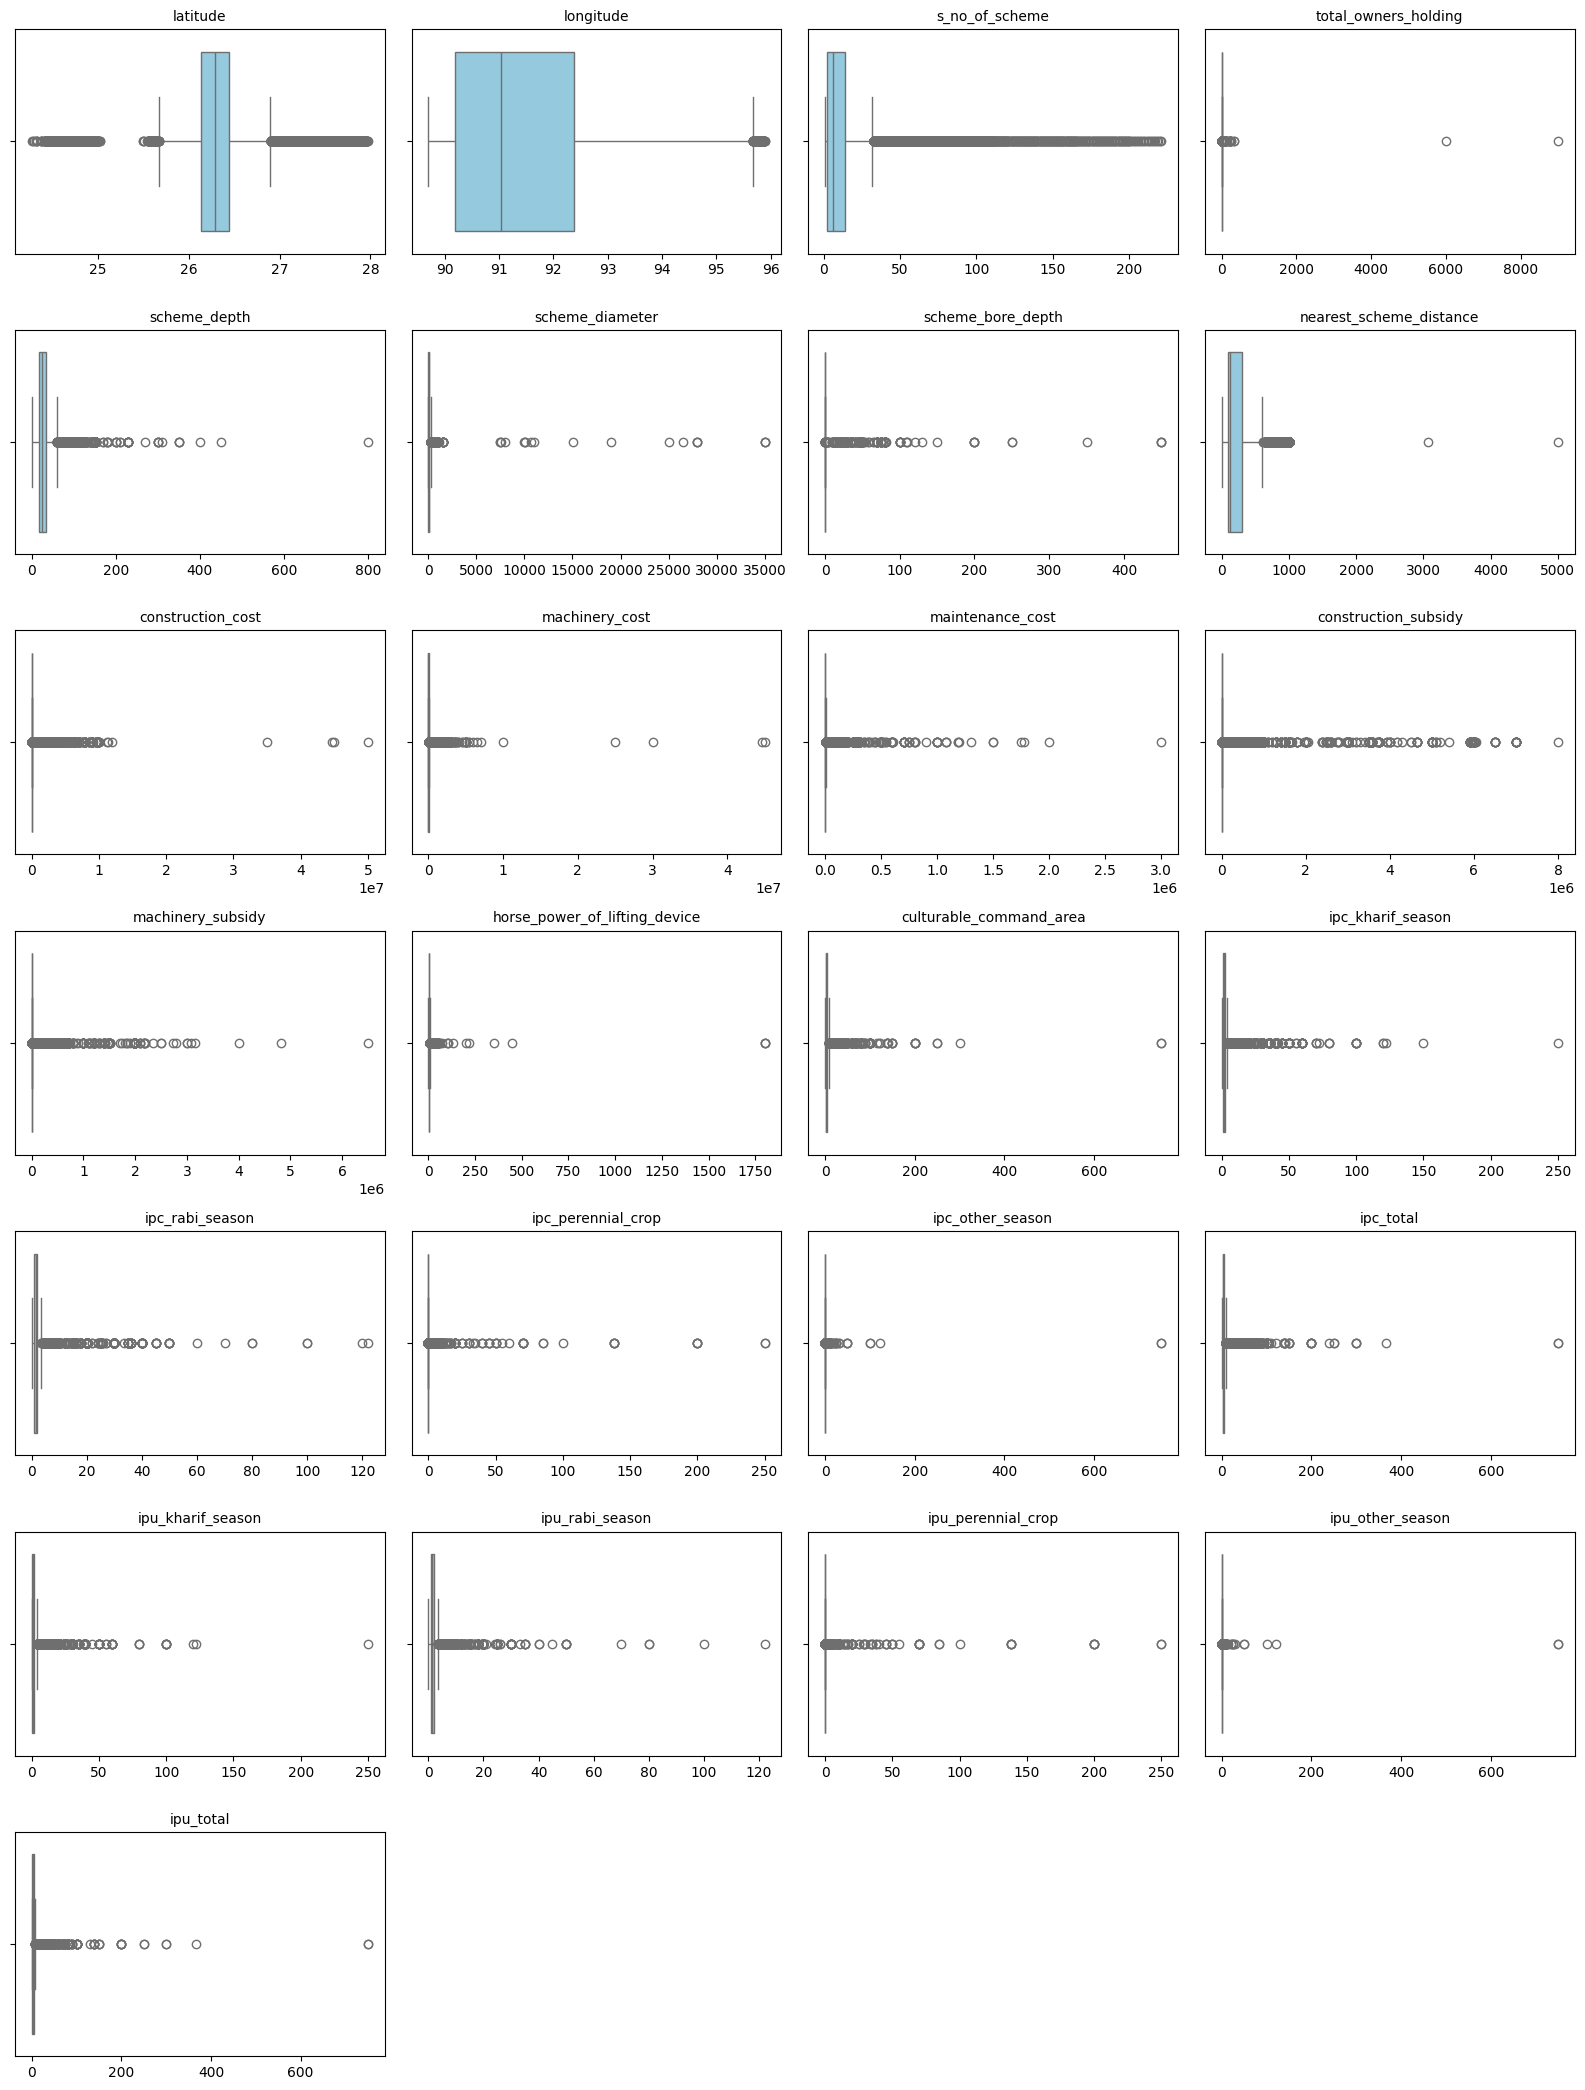

In [4]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

ncols = 4
nrows = math.ceil(len(numeric_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x=df_clean[col], ax=ax, color="skyblue")
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")

for ax in axes[len(numeric_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

### Histogram

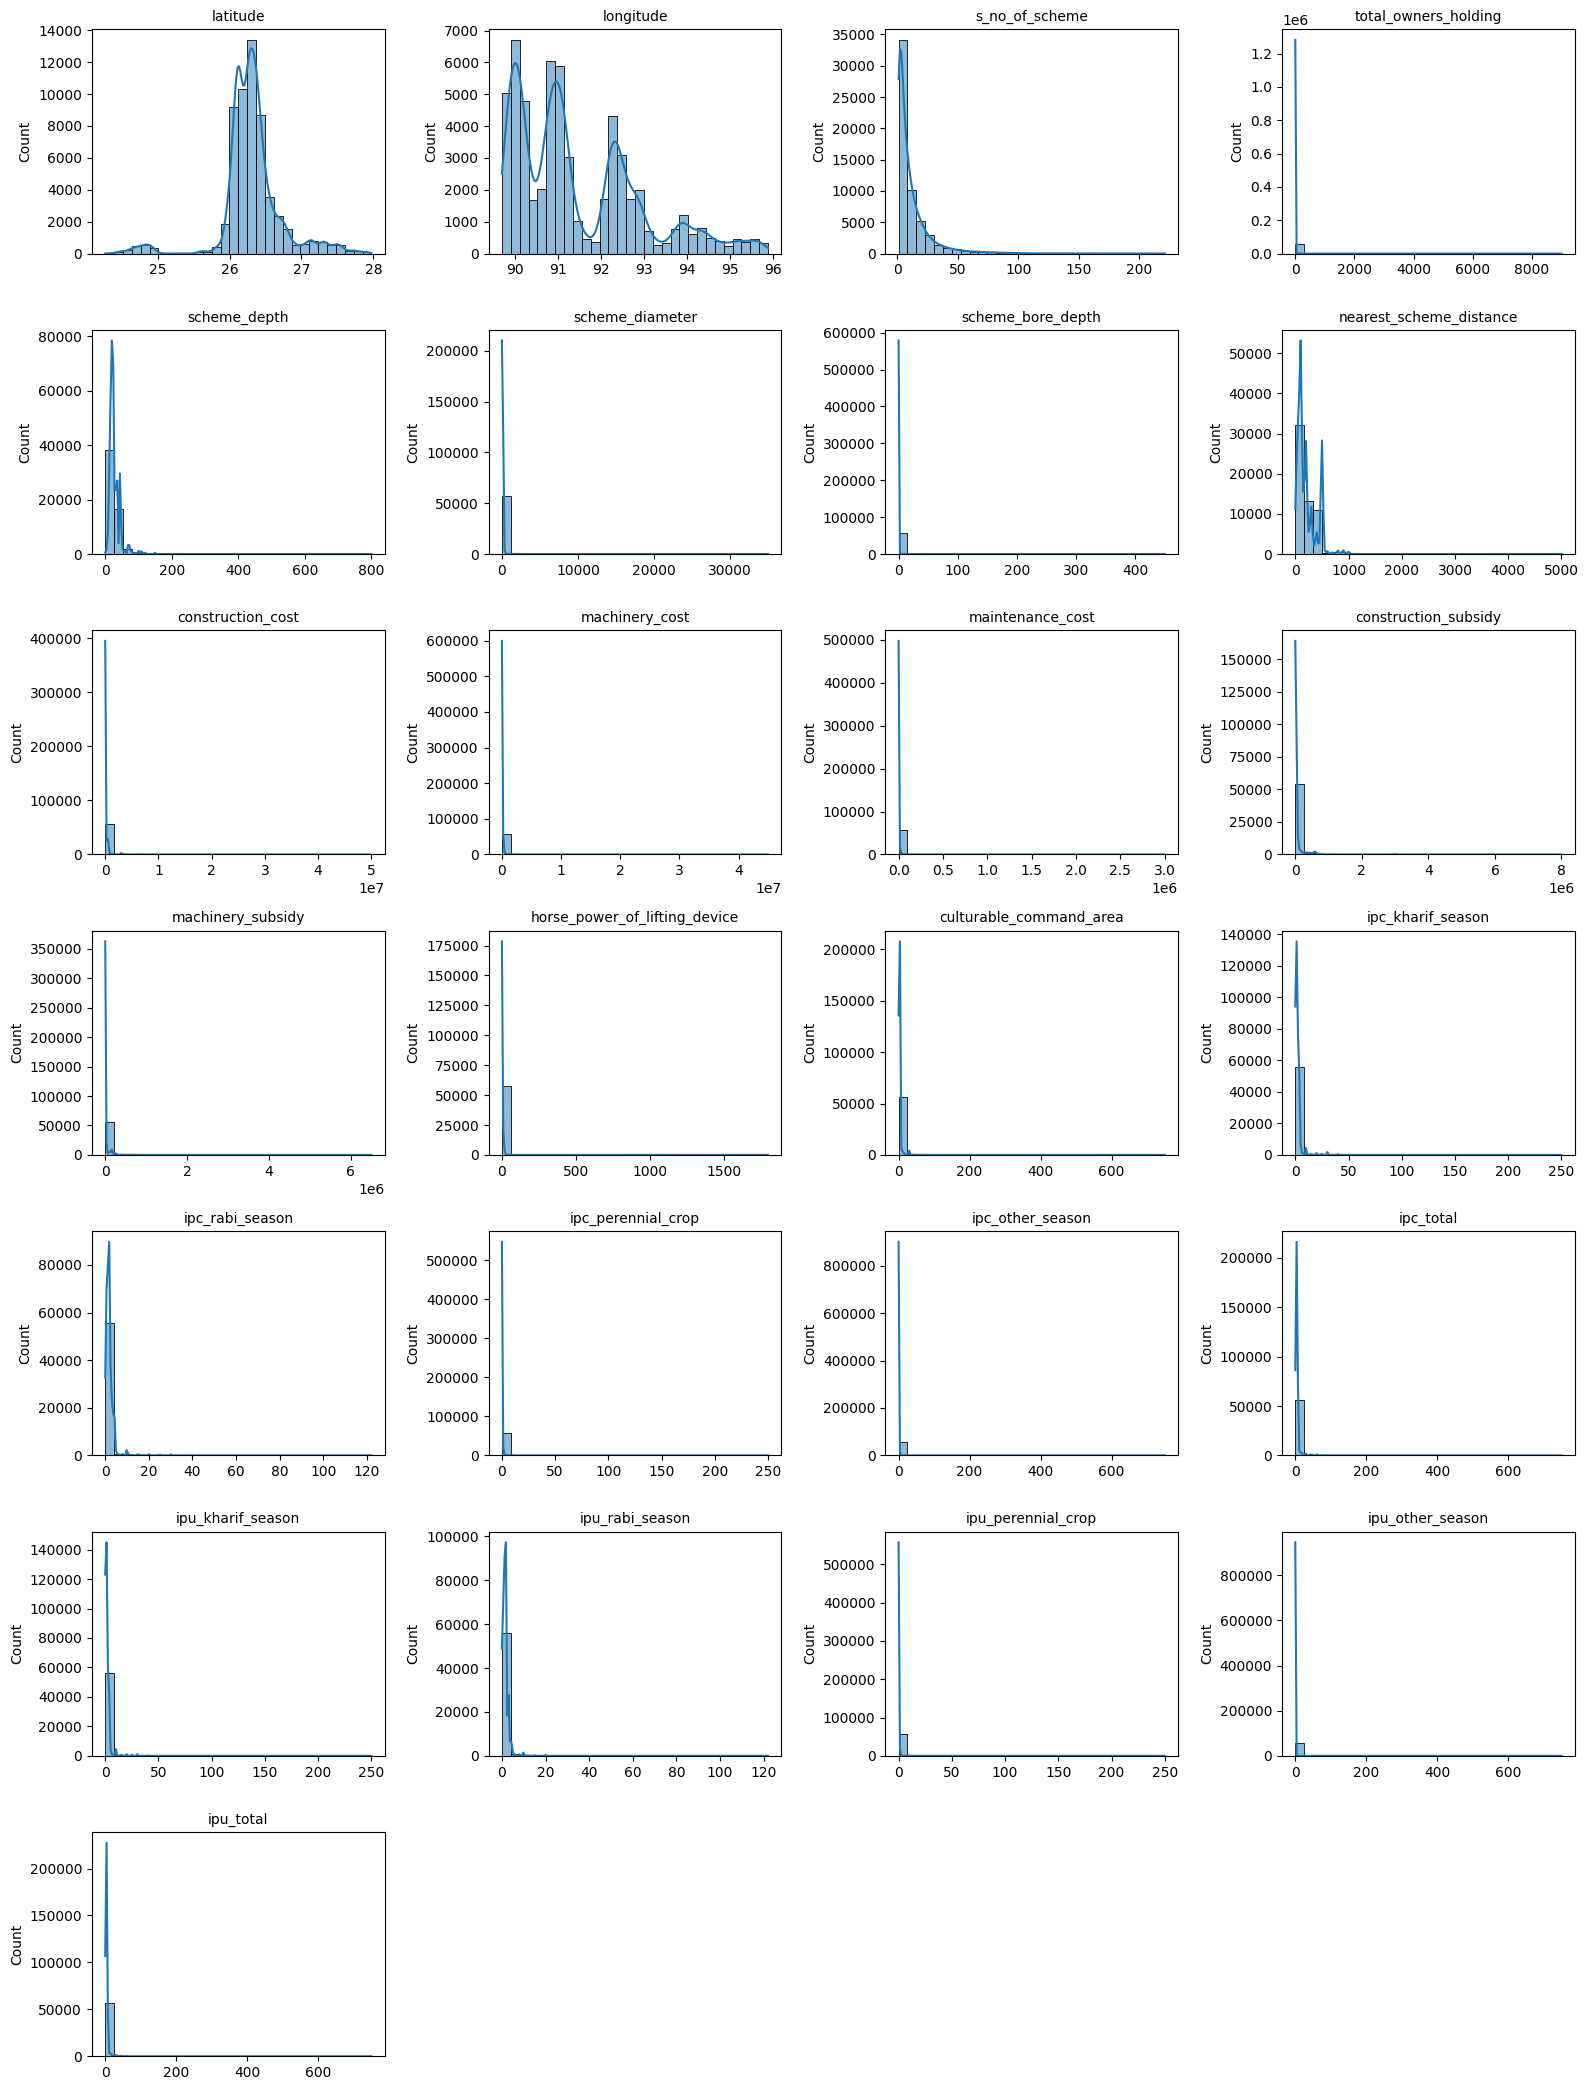

In [5]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

ncols = 4
nrows = math.ceil(len(numeric_cols) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3 * nrows))
axes = axes.flatten()

for ax, col in zip(axes, numeric_cols):
    sns.histplot(df_clean[col].dropna(), bins=30, kde=True, ax=ax)
    ax.set_title(col, fontsize=10)
    ax.set_xlabel("")

for ax in axes[len(numeric_cols):]:
    ax.remove()

plt.tight_layout()
plt.show()

### Scatterplot

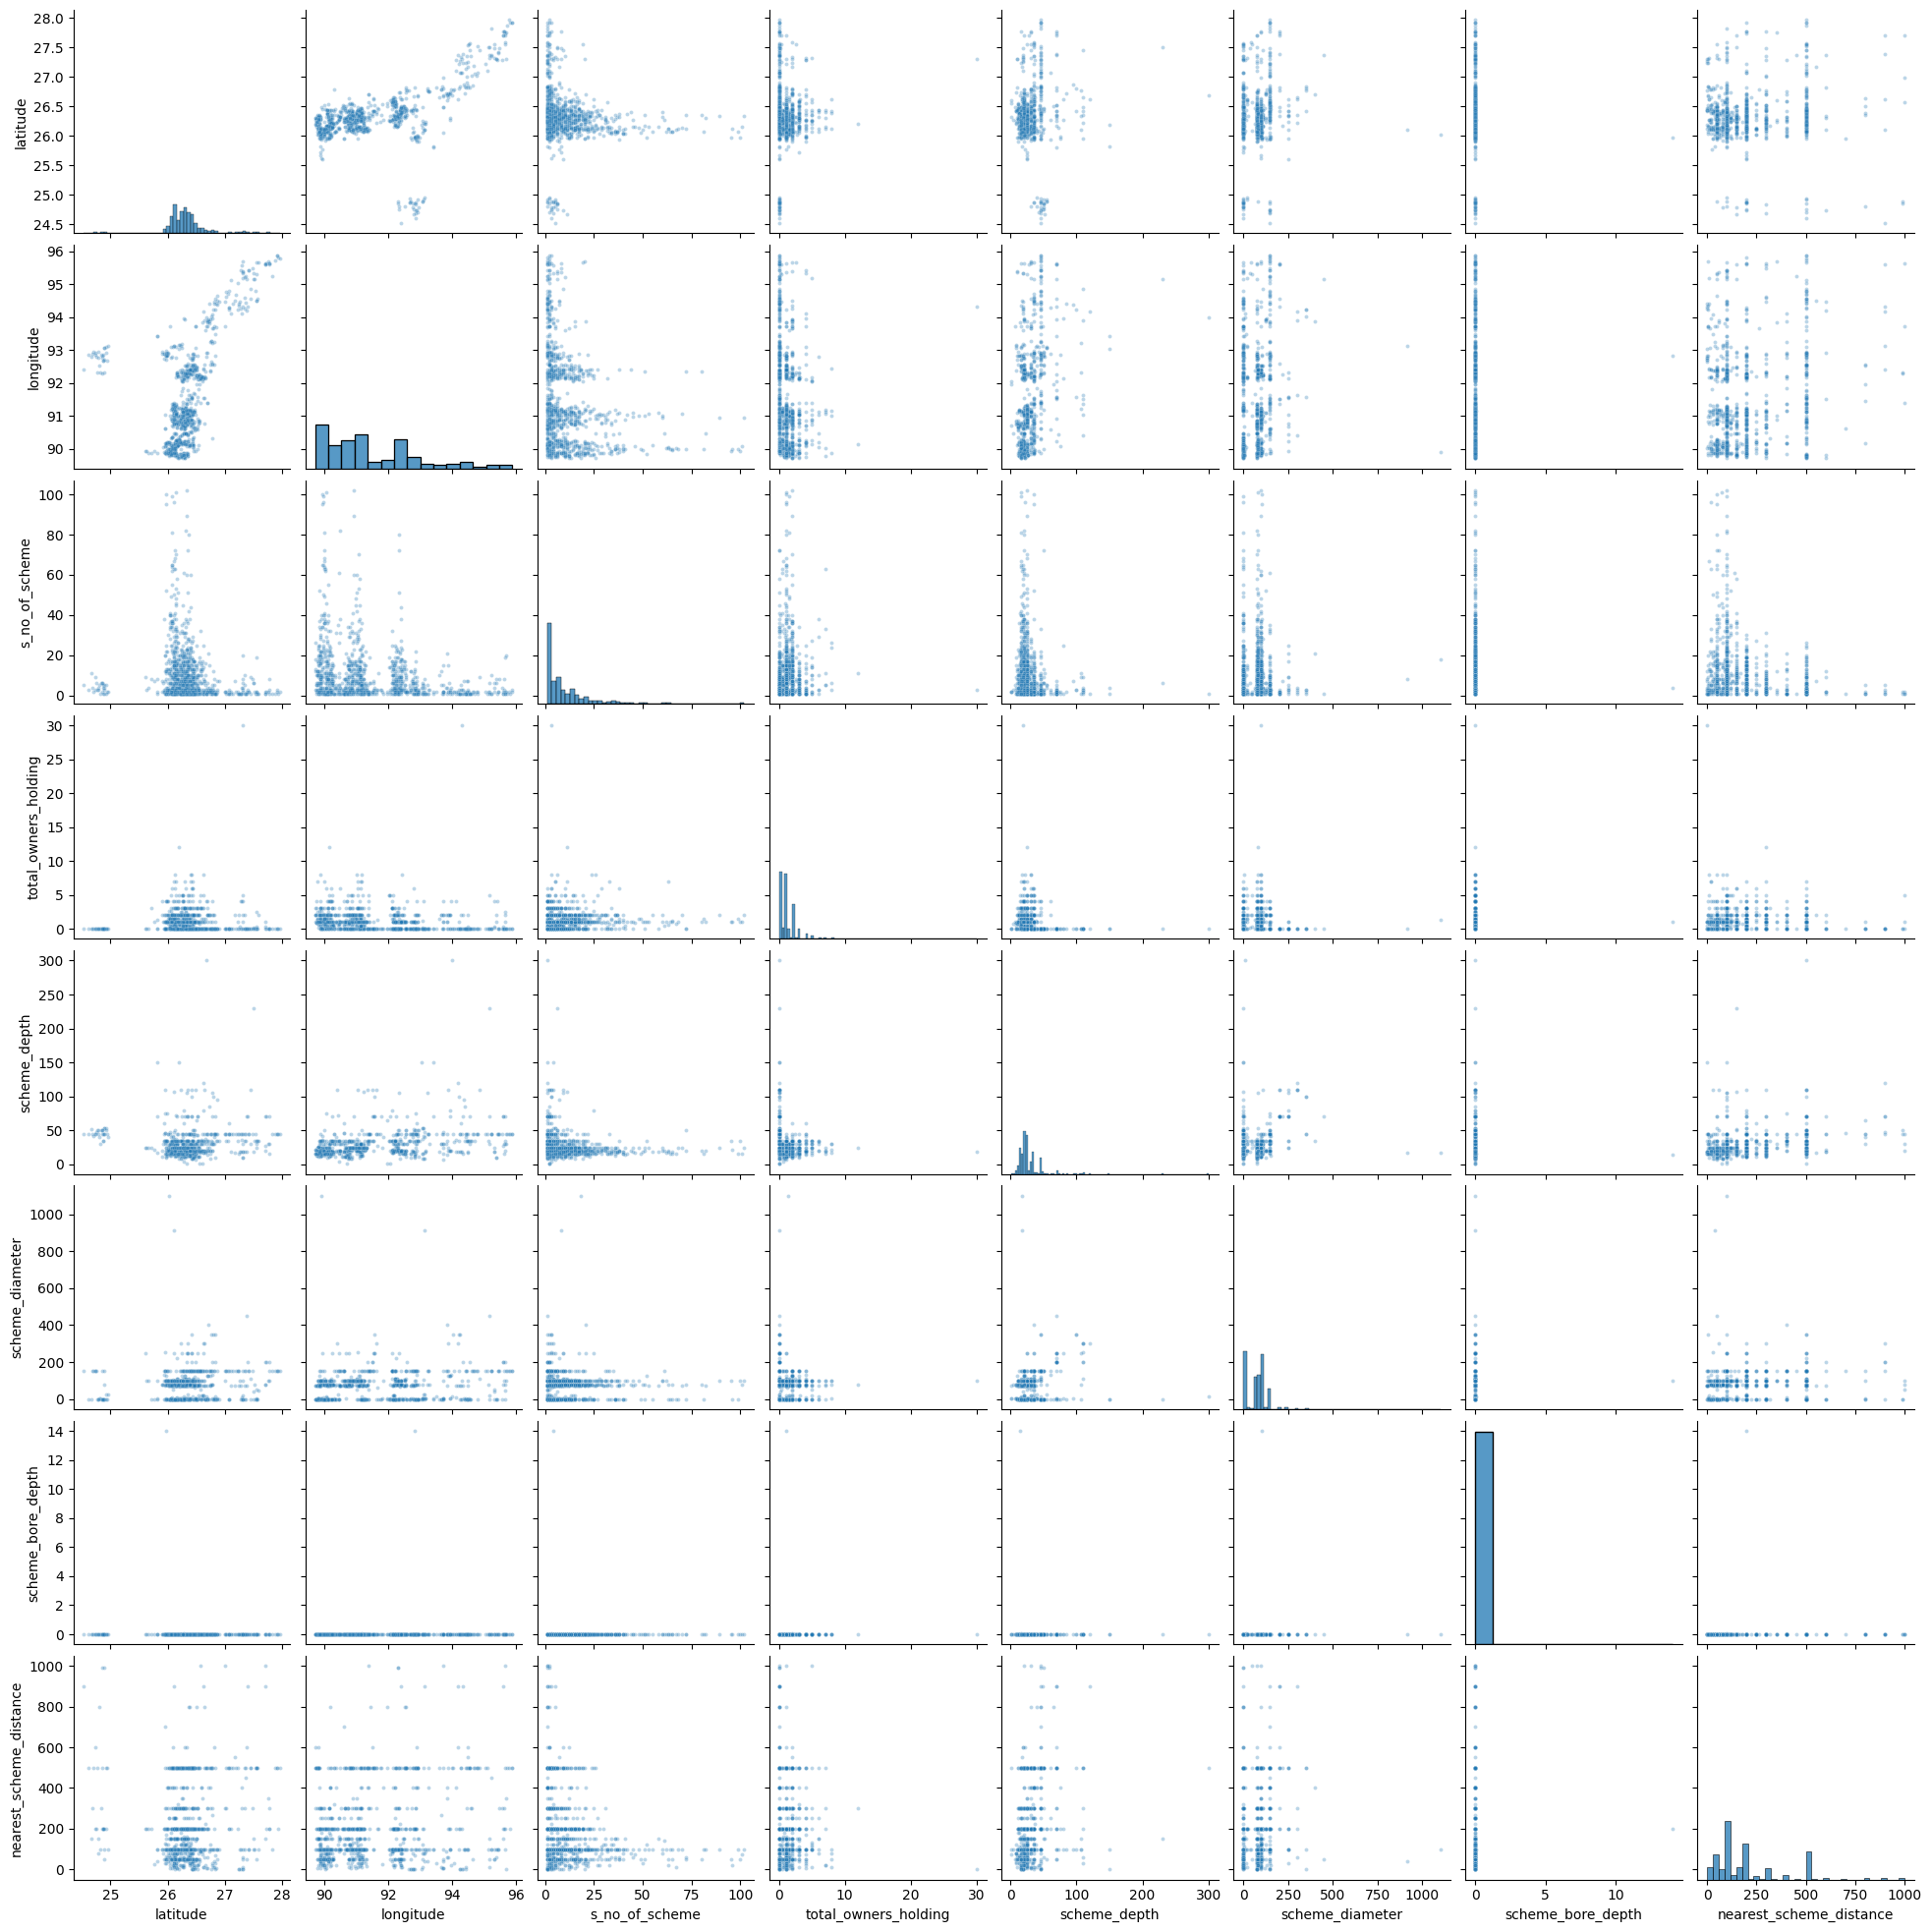

In [6]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns.tolist()

# Limit to first 8 numeric columns
cols = numeric_cols[:8]

# Sample at most 1000 rows
df_sample = df_clean[cols].sample(
    n=min(1000, len(df_clean)), random_state=42
)

# Generate scatter plots
sns.pairplot(
    df_sample,
    diag_kind="hist",
    plot_kws={"alpha": 0.3, "s": 8}
)

plt.show()

# Statistical

### IQR

In [7]:
import pandas as pd

# Calculate IQR and identify outliers for every numeric column
numeric_cols = df_clean.select_dtypes(include="number").columns

iqr_results = []

for col in numeric_cols:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = ((df_clean[col] < lower_bound) |
                (df_clean[col] > upper_bound)).sum()

    iqr_results.append({
        "Column": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outliers": outliers
    })

iqr_df = pd.DataFrame(iqr_results)

display(iqr_df.round(2))

,Column,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers
0,latitude,26.13,26.44,0.31,25.67,26.90,5740
1,longitude,90.19,92.38,2.20,86.89,95.67,353
2,s_no_of_scheme,2.00,14.00,12.00,-16.00,32.00,4384
3,total_owners_holding,0.00,2.00,2.00,-3.00,5.00,851
4,scheme_depth,18.00,35.00,17.00,-7.50,60.50,2268
5,scheme_diameter,12.00,100.00,88.00,-120.00,232.00,1110
6,scheme_bore_depth,0.00,0.00,0.00,0.00,0.00,275
7,nearest_scheme_distance,100.00,300.00,200.00,-200.00,600.00,886
8,construction_cost,10000.00,35000.00,25000.00,-27500.00,72500.00,11806
9,machinery_cost,10200.00,35000.00,24800.00,-27000.00,72200.00,10648


### Z-Score

In [8]:
import pandas as pd
import numpy as np

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Calculate Z-scores
z_scores = (
    (df_clean[numeric_cols] - df_clean[numeric_cols].mean())
    / df_clean[numeric_cols].std()
)

# Count outliers in each column
z_results = pd.DataFrame({
    "Column": numeric_cols,
    "Mean": df_clean[numeric_cols].mean().values,
    "Std Dev": df_clean[numeric_cols].std().values,
    "Outliers (|Z| > 3)": (z_scores.abs() > 3).sum().values
})

display(z_results.round(2))

,Column,Mean,Std Dev,Outliers (|Z| > 3)
0,latitude,26.31,0.42,2086
1,longitude,91.46,1.45,76
2,s_no_of_scheme,11.90,17.41,1183
3,total_owners_holding,1.56,45.36,14
4,scheme_depth,27.47,17.32,1001
5,scheme_diameter,84.85,394.26,27
6,scheme_bore_depth,0.23,5.28,222
7,nearest_scheme_distance,205.60,180.27,754
8,construction_cost,157764.65,675397.14,897
9,machinery_cost,74317.77,377548.03,372


### Outlars in IQR and Z-Socre

In [9]:
import pandas as pd
import numpy as np

numeric_cols = df_clean.select_dtypes(include="number").columns
results = []

for col in numeric_cols:
    s = df_clean[col].dropna()

    # IQR outliers
    Q1 = s.quantile(0.25)
    Q3 = s.quantile(0.75)
    IQR = Q3 - Q1

    iqr_mask = (s < Q1 - 1.5 * IQR) | (s > Q3 + 1.5 * IQR)

    # Z-score outliers
    std = s.std()

    if std == 0 or pd.isna(std):
        z_mask = pd.Series(False, index=s.index)
    else:
        z_scores = (s - s.mean()) / std
        z_mask = z_scores.abs() > 3

    # Counts
    results.append({
        "Column": col,
        "IQR Outliers": iqr_mask.sum(),
        "Z-Score Outliers": z_mask.sum(),
        "Outliers in Both": (iqr_mask & z_mask).sum()
    })

outlier_summary = pd.DataFrame(results)

display(outlier_summary)

,Column,IQR Outliers,Z-Score Outliers,Outliers in Both
0,latitude,5740,2086,2086
1,longitude,353,76,76
2,s_no_of_scheme,4384,1183,1183
3,total_owners_holding,851,14,14
4,scheme_depth,2268,1001,1001
5,scheme_diameter,1110,27,27
6,scheme_bore_depth,275,222,222
7,nearest_scheme_distance,886,754,754
8,construction_cost,11806,897,897
9,machinery_cost,10648,372,372


# Proximity based

### Local Outlier Factor

In [10]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import LocalOutlierFactor

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Prepare data
X = df_clean[numeric_cols].replace([float("inf"), -float("inf")], float("nan"))
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

# LOF detection
lof = LocalOutlierFactor(n_neighbors=20, contamination="auto")
labels = lof.fit_predict(X)

# -1 = outlier, 1 = inlier
df_lof = df_clean.copy()
df_lof["LOF_Outlier"] = labels == -1

# Summary
print("Total rows:", len(df_lof))
print("LOF outliers:", (labels == -1).sum())
print("Normal rows:", (labels == 1).sum())

# Display detected outliers
display(df_lof[df_lof["LOF_Outlier"]])

Total rows: 57303
LOF outliers: 5227
Normal rows: 52076


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_rabi_season,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,LOF_Outlier
3,Dhubri,Nayeralga,Boalkamri Pt.Iii,26.210017,90.160672,4,Tube well,Owned by individual farmer,0.3,Others,...,1.5,0.0,0.0,3.5,No,No,No,Tubewell: Shallow Tube well,Own savings,True
16,Dhubri,Nayeralga,Dalaner Alga No.2,26.177529,90.119815,4,Tube well,Others,0.0,Not applicable,...,2.0,0.0,0.0,4.0,No,No,No,Tubewell: Shallow Tube well,Others,True
22,Dibrugarh,Lahoal,Laimekuri Chapori,27.751024,95.082172,1,Tube well,Govt. Owned,0.0,Not applicable,...,2.0,0.0,0.0,4.0,No,No,No,Tubewell: Shallow Tube well,Government fund,True
26,Goalpara,Kuchdhowa,Thekashu Pt.-Ii (Ct),25.975817,90.791785,2,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,0.0,NaN,No,No,Tubewell: Shallow Tube well,Government fund,True
27,Goalpara,Kuchdhowa,Thekashu Pt.-Ii (Ct),25.975279,90.792665,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,0.0,NaN,No,No,Tubewell: Shallow Tube well,Government fund,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57281,Barpeta,Mandia,Satra Kanara N.C.,26.237119,90.880735,156,Tube well,Others,0.0,Not applicable,...,2.5,0.0,0.0,3.5,NaN,No,No,Tubewell: Medium Tube well,Others,True
57282,Barpeta,Mandia,Satra Kanara N.C.,26.252968,90.895125,161,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,0.0,NaN,No,No,Tubewell: Medium Tube well,Government fund,True
57283,Karimganj,Badarpur,Hasanpur,24.857325,92.512547,4,Tube well,Others,0.0,Not applicable,...,2.0,0.0,0.0,10.0,NaN,No,No,Tubewell: Shallow Tube well,Others,True
57291,Kokrajhar,Kokrajhar,Kurshakati Pt. I,26.461314,90.387955,1,Tube well,Owned by individual farmer,2.0,Scheduled-tribe,...,0.5,0.0,0.0,2.0,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",True


# Clustering Based

### DBSCAN

In [11]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.cluster import DBSCAN

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Prepare data
X = df_clean[numeric_cols].replace([float("inf"), -float("inf")], float("nan"))
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

# DBSCAN clustering
dbscan = DBSCAN(eps=0.5, min_samples=5, n_jobs=-1)
labels = dbscan.fit_predict(X)

# Add results
df_dbscan = df_clean.copy()
df_dbscan["Cluster"] = labels
df_dbscan["DBSCAN_Outlier"] = labels == -1

# Summary
print("Total rows:", len(df_dbscan))
print("Number of clusters:", len(set(labels) - {-1}))
print("Number of outliers:", (labels == -1).sum())
print("Normal rows:", (labels != -1).sum())

# Display outlier rows
display(df_dbscan[df_dbscan["DBSCAN_Outlier"]])

Total rows: 57303
Number of clusters: 621
Number of outliers: 11395
Normal rows: 45908


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,Cluster,DBSCAN_Outlier
0,Goalpara,Kuchdhowa,Siluk Pt-Ii,25.956992,90.799726,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,5.0,NaN,No,No,Tubewell: Medium Tube well,Government fund,-1,True
2,Goalpara,Kuchdhowa,Patiarpara Pt-I,25.971319,90.917621,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,4.0,NaN,No,Yes,Tubewell: Medium Tube well,Government fund,-1,True
15,Dhubri,Nayeralga,Dalaner Alga No.2,26.181315,90.120688,1,Tube well,Owned by individual farmer,1.0,Others,...,0.0,0.0,7.5,No,No,No,Tubewell: Shallow Tube well,Own savings,-1,True
16,Dhubri,Nayeralga,Dalaner Alga No.2,26.177529,90.119815,4,Tube well,Others,0.0,Not applicable,...,0.0,0.0,4.0,No,No,No,Tubewell: Shallow Tube well,Others,-1,True
17,Dhubri,Nayeralga,Dalaner Alga No.2,26.175717,90.118580,2,Tube well,Owned by individual farmer,1.0,Others,...,0.0,0.0,7.5,No,No,No,Tubewell: Shallow Tube well,Own savings,-1,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57290,Cachar,Udharbond,Kashipur Pt-I,24.811391,92.847315,3,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,2.0,11.0,Yes,No,No,Tubewell: Medium Tube well,Government fund,-1,True
57291,Kokrajhar,Kokrajhar,Kurshakati Pt. I,26.461314,90.387955,1,Tube well,Owned by individual farmer,2.0,Scheduled-tribe,...,0.0,0.0,2.0,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",-1,True
57293,Udalguri,Odalguri,Amjuli No.3,26.841532,92.033643,2,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,No,Yes,No,Tubewell: Shallow Tube well,Government fund,-1,True
57301,Hojai,Dhalpukhuri,Pam Gaon,25.983986,92.916069,16,Tube well,Panchayat Owned,0.0,Not applicable,...,0.0,0.0,4.0,No,No,No,Tubewell: Artesian Well,Panchayat Owned,-1,True


# ML Based

### Isolation Forest

In [12]:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Prepare data
X = df_clean[numeric_cols].replace([float("inf"), -float("inf")], float("nan"))
X = SimpleImputer(strategy="median").fit_transform(X)

# Isolation Forest
model = IsolationForest(
    n_estimators=100,
    contamination="auto",
    random_state=42,
    n_jobs=-1
)

labels = model.fit_predict(X)

# Add results
df_isolation = df_clean.copy()
df_isolation["Isolation_Outlier"] = labels == -1

# Summary
print("Total rows:", len(df_isolation))
print("Outliers:", (labels == -1).sum())
print("Normal rows:", (labels == 1).sum())

# Display outlier rows
display(df_isolation[df_isolation["Isolation_Outlier"]])

Total rows: 57303
Outliers: 2472
Normal rows: 54831


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_rabi_season,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,Isolation_Outlier
47,Kamrup,Bihdia -Jajikona,Muktapur,26.439953,91.722332,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,0.0,No,Yes,No,Tubewell: Deep Tube well,Government fund,True
55,Kamrup,Bihdia -Jajikona,Loch,26.432798,91.734537,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,0.0,No,Yes,No,Tubewell: Deep Tube well,Government fund,True
73,Jorhat,Jorhat East,Gharphalia Gaon,26.719807,94.463250,1,Tube well,Owned by Group of farmers,0.0,Not applicable,...,5.0,5.0,0.0,50.0,No,No,No,Tubewell: Deep Tube well,Owned by Group of farmers,True
74,Jorhat,Jorhat East,Gharphalia Gaon,26.719773,94.463252,2,Tube well,Owned by Group of farmers,0.0,Not applicable,...,5.0,5.0,0.0,50.0,No,Yes,No,Tubewell: Deep Tube well,Owned by Group of farmers,True
80,Jorhat,Kaliapani,Tulashijonia Pohumora Gaon,26.865845,94.458647,5,Tube well,Govt. Owned,0.0,Not applicable,...,10.0,10.0,0.0,60.0,No,No,No,Tubewell: Medium Tube well,Government fund,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57229,Charaideo,Mahmara,1.No.Khumtai T.E,27.180595,94.947168,1,Tube well,Govt. Owned,0.0,Not applicable,...,5.0,0.0,0.0,15.0,No,No,No,Tubewell: Medium Tube well,Government fund,True
57233,Charaideo,Mahmara,Kurukani F.V,27.132284,95.049044,2,Tube well,Govt. Owned,0.0,Not applicable,...,7.0,0.0,0.0,17.0,No,No,No,Tubewell: Deep Tube well,Government fund,True
57258,Barpeta,Pakabetbari,Bhakuamari,26.399831,91.082564,22,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,0.0,No,No,No,Tubewell: Deep Tube well,Government fund,True
57271,Biswanath,Baghmara,Bihpukhuri T.E.,26.773046,93.223090,1,Tube well,Govt. Owned,0.0,Not applicable,...,10.0,0.0,0.0,22.0,NaN,No,No,Tubewell: Deep Tube well,Government fund,True


### One-Class Support Vector Machine

In [13]:
import pandas as pd
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Prepare data
X = df_clean[numeric_cols].replace([float("inf"), -float("inf")], float("nan"))
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

# One-Class SVM
model = OneClassSVM(
    kernel="rbf",
    nu=0.05,
    gamma="scale"
)

labels = model.fit_predict(X)

# Add results
df_svm = df_clean.copy()
df_svm["SVM_Outlier"] = labels == -1

# Summary
print("Total rows:", len(df_svm))
print("Outliers:", (labels == -1).sum())
print("Normal rows:", (labels == 1).sum())

# Display outlier rows
display(df_svm[df_svm["SVM_Outlier"]])

Total rows: 57303
Outliers: 2866
Normal rows: 54437


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_rabi_season,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,SVM_Outlier
47,Kamrup,Bihdia -Jajikona,Muktapur,26.439953,91.722332,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,0.0,No,Yes,No,Tubewell: Deep Tube well,Government fund,True
55,Kamrup,Bihdia -Jajikona,Loch,26.432798,91.734537,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,0.0,No,Yes,No,Tubewell: Deep Tube well,Government fund,True
72,Cachar,Palonghat,Sentcatherine,24.599489,92.961460,2,Tube well,Govt. Owned,0.0,Not applicable,...,2.0,0.0,0.0,4.0,No,No,Yes,Tubewell: Medium Tube well,Government fund,True
73,Jorhat,Jorhat East,Gharphalia Gaon,26.719807,94.463250,1,Tube well,Owned by Group of farmers,0.0,Not applicable,...,5.0,5.0,0.0,50.0,No,No,No,Tubewell: Deep Tube well,Owned by Group of farmers,True
74,Jorhat,Jorhat East,Gharphalia Gaon,26.719773,94.463252,2,Tube well,Owned by Group of farmers,0.0,Not applicable,...,5.0,5.0,0.0,50.0,No,Yes,No,Tubewell: Deep Tube well,Owned by Group of farmers,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57280,Barpeta,Mandia,Satra Kanara N.C.,26.240593,90.895625,155,Tube well,Others,0.0,Not applicable,...,2.5,0.0,0.0,3.5,NaN,No,No,Tubewell: Medium Tube well,Others,True
57281,Barpeta,Mandia,Satra Kanara N.C.,26.237119,90.880735,156,Tube well,Others,0.0,Not applicable,...,2.5,0.0,0.0,3.5,NaN,No,No,Tubewell: Medium Tube well,Others,True
57282,Barpeta,Mandia,Satra Kanara N.C.,26.252968,90.895125,161,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,0.0,NaN,No,No,Tubewell: Medium Tube well,Government fund,True
57286,Karimganj,Badarpur,Nagkapan Pt I,24.810225,92.337363,1,Dug well,Owned by individual farmer,1.0,Others,...,2.0,0.0,0.0,5.0,No,Yes,No,Dugwell: Dug-cum-bore well,"Others, Own savings",True


### Autoencoders

In [14]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.callbacks import EarlyStopping

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Prepare data
X = df_clean[numeric_cols].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
scaler = StandardScaler()
X = scaler.fit_transform(X).astype("float32")

# Build autoencoder
n_features = X.shape[1]
inputs = Input(shape=(n_features,))
encoded = Dense(max(1, n_features // 2), activation="relu")(inputs)
encoded = Dense(max(1, n_features // 4), activation="relu")(encoded)
decoded = Dense(max(1, n_features // 2), activation="relu")(encoded)
outputs = Dense(n_features, activation="linear")(decoded)

autoencoder = Model(inputs, outputs)
autoencoder.compile(optimizer="adam", loss="mse")

# Train
autoencoder.fit(
    X, X,
    epochs=50,
    batch_size=256,
    validation_split=0.1,
    callbacks=[EarlyStopping(patience=5, restore_best_weights=True)],
    shuffle=True,
    verbose=1
)

# Calculate reconstruction error
reconstructed = autoencoder.predict(X, batch_size=1024, verbose=0)
errors = np.mean(np.square(X - reconstructed), axis=1)

# Flag top 5% highest-error rows
threshold = np.quantile(errors, 0.95)
labels = errors > threshold

# Results
df_autoencoder = df_clean.copy()
df_autoencoder["Reconstruction_Error"] = errors
df_autoencoder["Autoencoder_Outlier"] = labels

print("Total rows:", len(df_autoencoder))
print("Outliers:", labels.sum())
print("Normal rows:", (~labels).sum())

display(
    df_autoencoder[df_autoencoder["Autoencoder_Outlier"]]
    .sort_values("Reconstruction_Error", ascending=False)
)

Epoch 1/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.8802 - val_loss: 1.1107
Epoch 2/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.6404 - val_loss: 0.9428
Epoch 3/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.5497 - val_loss: 0.9019
Epoch 4/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.5145 - val_loss: 0.8810
Epoch 5/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4850 - val_loss: 0.8738
Epoch 6/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.4549 - val_loss: 0.8487
Epoch 7/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4303 - val_loss: 0.8231
Epoch 8/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.4056 - val_loss: 0.8107
Epoch 9/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3880 - val_loss: 0.8076
Epoch 10/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3781 - val_loss: 0.8031
Epoch 11/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.3564 - val_loss: 0.7978
Epoch 12/50
202/202 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,Reconstruction_Error,Autoencoder_Outlier
56735,Dhubri,Birshing-Jarua,Salmara Pt. VIII,26.133979,90.133951,2,Tube well,Owned by individual farmer,9000.0,Others,...,0.0,0.0,4.000,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",1589.491455,True
56736,Dhubri,Birshing-Jarua,Salmara Pt. VIII,26.133863,90.133854,3,Tube well,Owned by individual farmer,6000.0,Others,...,0.0,0.0,4.000,No,No,No,Tubewell: Shallow Tube well,Own savings,706.438538,True
34950,Marigaon,Mayang,Barhampur,26.231604,92.146595,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.000,No,No,No,Tubewell: Shallow Tube well,Government fund,416.646118,True
41945,Dibrugarh,Khowang,Konwar Gaon No.1,27.262890,94.825238,2,Tube well,Owned by Group of farmers,0.0,Not applicable,...,0.0,0.0,25.000,No,No,No,Tubewell: Shallow Tube well,Owned by Group of farmers,376.521118,True
14547,Kamrup,Chamaria,Bagariguri,26.092818,91.134165,2,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,5.500,No,No,No,Tubewell: Shallow Tube well,Government fund,311.933868,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
36212,Bongaigaon,Tapattary,Bechimari,26.271871,90.601837,3,Tube well,Owned by individual farmer,4.0,Others,...,0.0,4.0,8.000,No,No,No,Tubewell: Medium Tube well,Government fund,0.387296,True
29840,Dhubri,Hatidhura,Bherbheri,26.307843,89.871815,4,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.8,1.999,No,No,No,Tubewell: Deep Tube well,Government fund,0.387292,True
40738,Majuli,Ujani Majuli,Phutchang,27.065022,94.368106,2,Tube well,Owned by individual farmer,5.0,OBC,...,0.0,0.0,8.000,Yes,No,No,Tubewell: Medium Tube well,"Government fund, Others",0.387227,True
27588,Cachar,Sonai,Rangirghat Pt II,24.730722,92.903030,3,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,4.000,NaN,Yes,No,Tubewell: Medium Tube well,Government fund,0.387175,True


# Multivariate Outlier Detection

### Isolation Forest

In [15]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.ensemble import IsolationForest

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Prepare data
X = df_clean[numeric_cols].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)

# Train Isolation Forest
model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

labels = model.fit_predict(X)
scores = model.decision_function(X)

# Store results
df_if = df_clean.copy()
df_if["Anomaly_Score"] = scores
df_if["Is_Outlier"] = labels == -1

# Summary
print("Total rows:", len(df_if))
print("Multivariate outliers:", (labels == -1).sum())
print("Normal rows:", (labels == 1).sum())

# Display outliers (highest anomaly first)
display(
    df_if[df_if["Is_Outlier"]]
    .sort_values("Anomaly_Score")
)

Total rows: 57303
Multivariate outliers: 2866
Normal rows: 54437


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,Anomaly_Score,Is_Outlier
28880,Kamrup,Rampur,Jalnamdani,26.103983,91.442374,4,Tube well,Govt. Owned,0.0,Not applicable,...,5.0,5.0,38.0,No,No,No,Tubewell: Medium Tube well,Government fund,-0.307146,True
14334,Kokrajhar,Kokrajhar,Daloabari Pt II,26.425928,90.187258,2,Tube well,Govt. Owned,0.0,Not applicable,...,3.0,5.0,58.0,No,No,No,Tubewell: Deep Tube well,Government fund,-0.306499,True
56577,Biswanath,Sakomatha,No.4 Pratapgarh S.P.P. No.1,26.747556,93.094318,1,Tube well,Others,0.0,Not applicable,...,20.0,10.0,100.0,No,No,No,Tubewell: Deep Tube well,Others,-0.306499,True
27513,Biswanath,Sakomatha,Pratap Garh 91/158,26.759987,93.091018,2,Tube well,Others,0.0,Not applicable,...,10.0,10.0,90.0,No,No,No,Tubewell: Deep Tube well,Others,-0.305963,True
27514,Biswanath,Sakomatha,Pratap Garh 91/158,26.742010,93.070527,1,Tube well,Others,0.0,Not applicable,...,10.0,10.0,90.0,No,No,No,Tubewell: Deep Tube well,Others,-0.305963,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
41816,Cachar,Udharbond,Kashipur Pt-I,24.814877,92.853528,6,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,2.0,10.0,Yes,No,No,Tubewell: Medium Tube well,Government fund,-0.000180,True
31701,Majuli,Ujani Majuli,Borbeel Bebejia,27.084475,94.369765,2,Tube well,Owned by individual farmer,2.0,OBC,...,0.0,0.0,0.0,Yes,No,No,Tubewell: Shallow Tube well,"Government fund, Others",-0.000161,True
2911,Barpeta,Gomaphulbari,Palhaji,26.259783,91.049841,15,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,NaN,No,No,Tubewell: Shallow Tube well,Government fund,-0.000128,True
14018,Cachar,Udharbond,Lathigram,24.876680,92.858430,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,8.0,Yes,No,No,Tubewell: Medium Tube well,Government fund,-0.000047,True


### Local Outlier Factor

In [16]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Prepare data
X = df_clean[numeric_cols].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

# LOF detection
model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    n_jobs=-1
)

labels = model.fit_predict(X)
scores = model.negative_outlier_factor_

# Store results
df_lof = df_clean.copy()
df_lof["LOF_Score"] = scores
df_lof["Is_Outlier"] = labels == -1

# Summary
print("Total rows:", len(df_lof))
print("Multivariate outliers:", (labels == -1).sum())
print("Normal rows:", (labels == 1).sum())

# Display outliers (most anomalous first)
display(
    df_lof[df_lof["Is_Outlier"]]
    .sort_values("LOF_Score")
)

Total rows: 57303
Multivariate outliers: 2866
Normal rows: 54437


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,LOF_Score,Is_Outlier
56735,Dhubri,Birshing-Jarua,Salmara Pt. VIII,26.133979,90.133951,2,Tube well,Owned by individual farmer,9000.0,Others,...,0.0,0.0,4.00,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",-57.172886,True
56736,Dhubri,Birshing-Jarua,Salmara Pt. VIII,26.133863,90.133854,3,Tube well,Owned by individual farmer,6000.0,Others,...,0.0,0.0,4.00,No,No,No,Tubewell: Shallow Tube well,Own savings,-39.385519,True
31242,Chirang,Borobazar,Chamugaon,26.518415,90.491031,1,Tube well,Owned by individual farmer,4.0,Scheduled-tribe,...,0.0,0.0,10.00,Yes,No,No,Tubewell: Shallow Tube well,"Others, Own savings",-25.681813,True
1660,Chirang,Borobazar,Malipara,26.569094,90.619542,1,Tube well,Others,0.0,Not applicable,...,0.0,0.0,7.00,Yes,No,No,Tubewell: Shallow Tube well,Others,-25.678083,True
1448,Chirang,Borobazar,Charai Khosara,26.561098,90.651870,2,Tube well,Owned by Group of farmers,0.0,Not applicable,...,0.0,0.0,7.00,Yes,No,No,Tubewell: Shallow Tube well,Owned by Group of farmers,-25.678036,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50941,Kamrup,Chamaria,Patheli Para,26.137522,91.116159,28,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,1.0,3.00,No,No,No,Tubewell: Medium Tube well,Government fund,-1.760656,True
42332,Kokrajhar,Gossaigaon,Kartaymari Pt.-Ii,26.350638,90.098127,2,Tube well,Owned by individual farmer,26.0,OBC,...,0.0,0.0,0.26,No,No,No,Tubewell: Shallow Tube well,"Money lender, Own savings",-1.760394,True
57209,Chirang,Borobazar,Fulkumari,26.599665,90.756077,6,Tube well,Owned by individual farmer,1.0,OBC,...,0.0,0.0,3.00,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",-1.760291,True
26638,Dhubri,Gauripur,Folimari Pt.Ii,26.058613,89.988077,43,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,3.0,9.00,Yes,No,No,Tubewell: Medium Tube well,Government fund,-1.760145,True


### Clustering Techniques

#### K-Means Clustering

In [17]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Prepare data
X = df_clean[numeric_cols].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

# K-Means clustering
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
labels = kmeans.fit_predict(X)

# Calculate distance from assigned centroid
distances = np.linalg.norm(
    X - kmeans.cluster_centers_[labels], axis=1
)

# Flag top 5% as potential outliers
threshold = np.quantile(distances, 0.95)

df_kmeans = df_clean.copy()
df_kmeans["Cluster"] = labels
df_kmeans["Distance"] = distances
df_kmeans["Is_Outlier"] = distances > threshold

print("Outliers:", df_kmeans["Is_Outlier"].sum())
display(df_kmeans[df_kmeans["Is_Outlier"]])

Outliers: 2866


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,Cluster,Distance,Is_Outlier
47,Kamrup,Bihdia -Jajikona,Muktapur,26.439953,91.722332,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,No,Yes,No,Tubewell: Deep Tube well,Government fund,0,15.438657,True
55,Kamrup,Bihdia -Jajikona,Loch,26.432798,91.734537,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,No,Yes,No,Tubewell: Deep Tube well,Government fund,0,15.360428,True
72,Cachar,Palonghat,Sentcatherine,24.599489,92.961460,2,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,4.0,No,No,Yes,Tubewell: Medium Tube well,Government fund,0,5.564378,True
73,Jorhat,Jorhat East,Gharphalia Gaon,26.719807,94.463250,1,Tube well,Owned by Group of farmers,0.0,Not applicable,...,0.0,50.0,No,No,No,Tubewell: Deep Tube well,Owned by Group of farmers,1,11.698011,True
74,Jorhat,Jorhat East,Gharphalia Gaon,26.719773,94.463252,2,Tube well,Owned by Group of farmers,0.0,Not applicable,...,0.0,50.0,No,Yes,No,Tubewell: Deep Tube well,Owned by Group of farmers,1,11.721223,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57280,Barpeta,Mandia,Satra Kanara N.C.,26.240593,90.895625,155,Tube well,Others,0.0,Not applicable,...,0.0,3.5,NaN,No,No,Tubewell: Medium Tube well,Others,0,8.362467,True
57281,Barpeta,Mandia,Satra Kanara N.C.,26.237119,90.880735,156,Tube well,Others,0.0,Not applicable,...,0.0,3.5,NaN,No,No,Tubewell: Medium Tube well,Others,0,8.420162,True
57282,Barpeta,Mandia,Satra Kanara N.C.,26.252968,90.895125,161,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,NaN,No,No,Tubewell: Medium Tube well,Government fund,0,8.761027,True
57286,Karimganj,Badarpur,Nagkapan Pt I,24.810225,92.337363,1,Dug well,Owned by individual farmer,1.0,Others,...,0.0,5.0,No,Yes,No,Dugwell: Dug-cum-bore well,"Others, Own savings",0,6.816208,True


#### Hierarchical Clustering

In [18]:
from sklearn.cluster import AgglomerativeClustering

# Sample rows for performance
sample_size = min(3000, len(df_clean))
df_sample = df_clean.sample(n=sample_size, random_state=42)

# Prepare sampled data
X_sample = df_sample[numeric_cols].replace(
    [np.inf, -np.inf], np.nan
)
X_sample = SimpleImputer(strategy="median").fit_transform(X_sample)
X_sample = StandardScaler().fit_transform(X_sample)

# Hierarchical clustering
hierarchical = AgglomerativeClustering(n_clusters=3)
labels = hierarchical.fit_predict(X_sample)

# Store results
df_hierarchical = df_sample.copy()
df_hierarchical["Cluster"] = labels

print("Cluster distribution:")
display(df_hierarchical["Cluster"].value_counts().sort_index())

display(df_hierarchical)

Cluster distribution:


Cluster
0      86
1    2912
2       2
Name: count, dtype: int64

,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_rabi_season,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,Cluster
24912,Nagaon,Moirabari Part,Mahkhuti,26.497566,92.465996,13,Tube well,Owned by individual farmer,2.0,Others,...,1.5,0.0,0.0,2.0,No,No,No,Tubewell: Shallow Tube well,"Government fund, Own savings",1
25927,Karbi Anglong,Samelangso,Bong-Et-Bey Gaon,26.253249,93.073229,1,Dug well,Others,0.0,Not applicable,...,1.0,0.5,0.5,6.0,No,Yes,No,Dugwell: Dug well Pucca,Others,1
36652,Barpeta,Barpeta,Hahchara,26.322575,91.121911,4,Tube well,Owned by individual farmer,2.0,Others,...,1.0,0.0,0.0,2.0,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",1
40095,Kokrajhar,Dotma,Lamapara,26.422036,90.126997,1,Tube well,Owned by individual farmer,1.0,OBC,...,1.0,0.0,0.0,3.0,No,Yes,No,Tubewell: Shallow Tube well,"Government fund, Own savings",1
49694,Kokrajhar,Gossaigaon,Dudumari-I,26.328162,90.072935,1,Tube well,Owned by individual farmer,1.0,Others,...,0.0,0.0,0.0,1.0,No,No,No,Tubewell: Shallow Tube well,"Money lender, Own savings",1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
22429,Goalpara,Jaleswar,Bhimkhaj,25.967016,90.143048,11,Tube well,Govt. Owned,0.0,Not applicable,...,1.0,0.0,0.0,5.0,No,No,No,Tubewell: Shallow Tube well,Government fund,1
51541,Dhubri,Mahamaya,Toppara Jhowpara Pt.I,26.158916,90.089446,17,Tube well,Owned by individual farmer,2.0,Others,...,2.0,0.0,2.0,6.0,Yes,No,No,Tubewell: Shallow Tube well,"Others, Own savings",1
12847,Kamrup,Goroimari,Salmara,26.150405,91.254338,2,Tube well,Owned by individual farmer,1.0,Others,...,1.5,0.0,0.0,3.0,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",1
22345,Marigaon,Mayang,Kuyadal,26.141510,92.179422,3,Tube well,Owned by individual farmer,1.0,Others,...,1.0,0.0,0.0,2.0,No,No,No,Tubewell: Shallow Tube well,Government fund,1


# ML-Based Multivariate

### Density-Based

#### KNN

In [19]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from pyod.models.knn import KNN

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Prepare data
X = df_clean[numeric_cols].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

# KNN detection
model = KNN(contamination=0.05, n_neighbors=20)
model.fit(X)

# Store results
df_knn = df_clean.copy()
df_knn["KNN_Score"] = model.decision_scores_
df_knn["KNN_Outlier"] = model.labels_ == 1

# Summary
print("Total rows:", len(df_knn))
print("Outliers:", df_knn["KNN_Outlier"].sum())
print("Normal rows:", (~df_knn["KNN_Outlier"]).sum())

display(
    df_knn[df_knn["KNN_Outlier"]]
    .sort_values("KNN_Score", ascending=False)
)

Total rows: 57303
Outliers: 2866
Normal rows: 54437


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,KNN_Score,KNN_Outlier
30263,Biswanath,Baghmara,Monabari T.E.P.P.No.1(Bihpukri,26.754593,93.242099,4,Tube well,Others,0.0,Not applicable,...,0.0,750.0,750.0,No,No,No,Tubewell: Deep Tube well,Others,275.545912,True
30262,Biswanath,Baghmara,Monabari T.E.P.P.No.1(Bihpukri,26.763137,93.236737,5,Tube well,Others,0.0,Not applicable,...,0.0,750.0,750.0,No,No,No,Tubewell: Deep Tube well,Others,275.400725,True
56735,Dhubri,Birshing-Jarua,Salmara Pt. VIII,26.133979,90.133951,2,Tube well,Owned by individual farmer,9000.0,Others,...,0.0,0.0,4.0,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",196.325934,True
56736,Dhubri,Birshing-Jarua,Salmara Pt. VIII,26.133863,90.133854,3,Tube well,Owned by individual farmer,6000.0,Others,...,0.0,0.0,4.0,No,No,No,Tubewell: Shallow Tube well,Own savings,130.190814,True
1660,Chirang,Borobazar,Malipara,26.569094,90.619542,1,Tube well,Others,0.0,Not applicable,...,0.0,0.0,7.0,Yes,No,No,Tubewell: Shallow Tube well,Others,129.059915,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3785,Sonitpur,Borchala,Benchimari Gaon,26.637740,92.519841,3,Tube well,Owned by individual farmer,6.0,Others,...,0.0,0.0,17.0,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",1.991188,True
51690,Kamrup,Rampur,Bartari,26.122048,91.412744,1,Tube well,Govt. Owned,0.0,Not applicable,...,2.0,2.0,12.0,No,No,No,Tubewell: Shallow Tube well,Government fund,1.990884,True
30523,Kamrup,Goroimari,Bihapara,26.089011,91.299017,4,Tube well,Owned by individual farmer,3.0,Others,...,0.0,1.0,3.0,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",1.990597,True
5866,Biswanath,Pub Chaiduar,Kalita Gaon,26.898055,93.743851,7,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,15.0,No,No,No,Tubewell: Medium Tube well,Government fund,1.990210,True


#### LOF

In [20]:
from pyod.models.lof import LOF

# LOF detection
model = LOF(contamination=0.05, n_neighbors=20)
model.fit(X)

# Store results
df_lof = df_clean.copy()
df_lof["LOF_Score"] = model.decision_scores_
df_lof["LOF_Outlier"] = model.labels_ == 1

# Summary
print("Total rows:", len(df_lof))
print("Outliers:", df_lof["LOF_Outlier"].sum())
print("Normal rows:", (~df_lof["LOF_Outlier"]).sum())

display(
    df_lof[df_lof["LOF_Outlier"]]
    .sort_values("LOF_Score", ascending=False)
)

Total rows: 57303
Outliers: 2866
Normal rows: 54437


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,LOF_Score,LOF_Outlier
56735,Dhubri,Birshing-Jarua,Salmara Pt. VIII,26.133979,90.133951,2,Tube well,Owned by individual farmer,9000.0,Others,...,0.0,0.0,4.00,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",57.172886,True
56736,Dhubri,Birshing-Jarua,Salmara Pt. VIII,26.133863,90.133854,3,Tube well,Owned by individual farmer,6000.0,Others,...,0.0,0.0,4.00,No,No,No,Tubewell: Shallow Tube well,Own savings,39.385519,True
31242,Chirang,Borobazar,Chamugaon,26.518415,90.491031,1,Tube well,Owned by individual farmer,4.0,Scheduled-tribe,...,0.0,0.0,10.00,Yes,No,No,Tubewell: Shallow Tube well,"Others, Own savings",25.681813,True
1660,Chirang,Borobazar,Malipara,26.569094,90.619542,1,Tube well,Others,0.0,Not applicable,...,0.0,0.0,7.00,Yes,No,No,Tubewell: Shallow Tube well,Others,25.678083,True
1448,Chirang,Borobazar,Charai Khosara,26.561098,90.651870,2,Tube well,Owned by Group of farmers,0.0,Not applicable,...,0.0,0.0,7.00,Yes,No,No,Tubewell: Shallow Tube well,Owned by Group of farmers,25.678036,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
50941,Kamrup,Chamaria,Patheli Para,26.137522,91.116159,28,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,1.0,3.00,No,No,No,Tubewell: Medium Tube well,Government fund,1.760656,True
42332,Kokrajhar,Gossaigaon,Kartaymari Pt.-Ii,26.350638,90.098127,2,Tube well,Owned by individual farmer,26.0,OBC,...,0.0,0.0,0.26,No,No,No,Tubewell: Shallow Tube well,"Money lender, Own savings",1.760394,True
57209,Chirang,Borobazar,Fulkumari,26.599665,90.756077,6,Tube well,Owned by individual farmer,1.0,OBC,...,0.0,0.0,3.00,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",1.760291,True
26638,Dhubri,Gauripur,Folimari Pt.Ii,26.058613,89.988077,43,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,3.0,9.00,Yes,No,No,Tubewell: Medium Tube well,Government fund,1.760145,True


### Clustering-Based

#### KNN

In [21]:
from pyod.models.knn import KNN

# KNN outlier detection
model = KNN(
    contamination=0.05,
    n_neighbors=20,
    method="largest",
    n_jobs=-1
)
model.fit(X)

# Store results
df_knn = df_clean.copy()
df_knn["KNN_Score"] = model.decision_scores_
df_knn["KNN_Outlier"] = model.labels_ == 1

# Summary
print("Total rows:", len(df_knn))
print("Outliers:", df_knn["KNN_Outlier"].sum())
print("Normal rows:", (~df_knn["KNN_Outlier"]).sum())

display(
    df_knn[df_knn["KNN_Outlier"]]
    .sort_values("KNN_Score", ascending=False)
)

Total rows: 57303
Outliers: 2866
Normal rows: 54437


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,KNN_Score,KNN_Outlier
30263,Biswanath,Baghmara,Monabari T.E.P.P.No.1(Bihpukri,26.754593,93.242099,4,Tube well,Others,0.0,Not applicable,...,0.0,750.0,750.0,No,No,No,Tubewell: Deep Tube well,Others,275.545912,True
30262,Biswanath,Baghmara,Monabari T.E.P.P.No.1(Bihpukri,26.763137,93.236737,5,Tube well,Others,0.0,Not applicable,...,0.0,750.0,750.0,No,No,No,Tubewell: Deep Tube well,Others,275.400725,True
56735,Dhubri,Birshing-Jarua,Salmara Pt. VIII,26.133979,90.133951,2,Tube well,Owned by individual farmer,9000.0,Others,...,0.0,0.0,4.0,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",196.325934,True
56736,Dhubri,Birshing-Jarua,Salmara Pt. VIII,26.133863,90.133854,3,Tube well,Owned by individual farmer,6000.0,Others,...,0.0,0.0,4.0,No,No,No,Tubewell: Shallow Tube well,Own savings,130.190814,True
1660,Chirang,Borobazar,Malipara,26.569094,90.619542,1,Tube well,Others,0.0,Not applicable,...,0.0,0.0,7.0,Yes,No,No,Tubewell: Shallow Tube well,Others,129.059915,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3785,Sonitpur,Borchala,Benchimari Gaon,26.637740,92.519841,3,Tube well,Owned by individual farmer,6.0,Others,...,0.0,0.0,17.0,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",1.991188,True
51690,Kamrup,Rampur,Bartari,26.122048,91.412744,1,Tube well,Govt. Owned,0.0,Not applicable,...,2.0,2.0,12.0,No,No,No,Tubewell: Shallow Tube well,Government fund,1.990884,True
30523,Kamrup,Goroimari,Bihapara,26.089011,91.299017,4,Tube well,Owned by individual farmer,3.0,Others,...,0.0,1.0,3.0,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",1.990597,True
5866,Biswanath,Pub Chaiduar,Kalita Gaon,26.898055,93.743851,7,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,15.0,No,No,No,Tubewell: Medium Tube well,Government fund,1.990210,True


#### DBSCAN


In [22]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Prepare data
X = df_clean[numeric_cols].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

# DBSCAN clustering
model = DBSCAN(eps=0.5, min_samples=5, n_jobs=-1)
labels = model.fit_predict(X)

# Store results
df_dbscan = df_clean.copy()
df_dbscan["Cluster"] = labels
df_dbscan["DBSCAN_Outlier"] = labels == -1

# Summary
print("Total rows:", len(df_dbscan))
print("Number of clusters:", len(set(labels) - {-1}))
print("Outliers:", (labels == -1).sum())
print("Normal rows:", (labels != -1).sum())

display(df_dbscan[df_dbscan["DBSCAN_Outlier"]])

Total rows: 57303
Number of clusters: 621
Outliers: 11395
Normal rows: 45908


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,Cluster,DBSCAN_Outlier
0,Goalpara,Kuchdhowa,Siluk Pt-Ii,25.956992,90.799726,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,5.0,NaN,No,No,Tubewell: Medium Tube well,Government fund,-1,True
2,Goalpara,Kuchdhowa,Patiarpara Pt-I,25.971319,90.917621,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,4.0,NaN,No,Yes,Tubewell: Medium Tube well,Government fund,-1,True
15,Dhubri,Nayeralga,Dalaner Alga No.2,26.181315,90.120688,1,Tube well,Owned by individual farmer,1.0,Others,...,0.0,0.0,7.5,No,No,No,Tubewell: Shallow Tube well,Own savings,-1,True
16,Dhubri,Nayeralga,Dalaner Alga No.2,26.177529,90.119815,4,Tube well,Others,0.0,Not applicable,...,0.0,0.0,4.0,No,No,No,Tubewell: Shallow Tube well,Others,-1,True
17,Dhubri,Nayeralga,Dalaner Alga No.2,26.175717,90.118580,2,Tube well,Owned by individual farmer,1.0,Others,...,0.0,0.0,7.5,No,No,No,Tubewell: Shallow Tube well,Own savings,-1,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57290,Cachar,Udharbond,Kashipur Pt-I,24.811391,92.847315,3,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,2.0,11.0,Yes,No,No,Tubewell: Medium Tube well,Government fund,-1,True
57291,Kokrajhar,Kokrajhar,Kurshakati Pt. I,26.461314,90.387955,1,Tube well,Owned by individual farmer,2.0,Scheduled-tribe,...,0.0,0.0,2.0,No,No,No,Tubewell: Shallow Tube well,"Others, Own savings",-1,True
57293,Udalguri,Odalguri,Amjuli No.3,26.841532,92.033643,2,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,No,Yes,No,Tubewell: Shallow Tube well,Government fund,-1,True
57301,Hojai,Dhalpukhuri,Pam Gaon,25.983986,92.916069,16,Tube well,Panchayat Owned,0.0,Not applicable,...,0.0,0.0,4.0,No,No,No,Tubewell: Artesian Well,Panchayat Owned,-1,True


## Support Vector Machine-Based

In [23]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Prepare data
X = df_clean[numeric_cols].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

# One-Class SVM
model = OneClassSVM(
    kernel="rbf",
    nu=0.05,
    gamma="scale"
)

labels = model.fit_predict(X)

# Store results
df_svm = df_clean.copy()
df_svm["SVM_Outlier"] = labels == -1

# Summary
print("Total rows:", len(df_svm))
print("Outliers:", df_svm["SVM_Outlier"].sum())
print("Normal rows:", (~df_svm["SVM_Outlier"]).sum())

# Display outliers
display(df_svm[df_svm["SVM_Outlier"]])

Total rows: 57303
Outliers: 2866
Normal rows: 54437


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_rabi_season,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,SVM_Outlier
47,Kamrup,Bihdia -Jajikona,Muktapur,26.439953,91.722332,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,0.0,No,Yes,No,Tubewell: Deep Tube well,Government fund,True
55,Kamrup,Bihdia -Jajikona,Loch,26.432798,91.734537,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,0.0,No,Yes,No,Tubewell: Deep Tube well,Government fund,True
72,Cachar,Palonghat,Sentcatherine,24.599489,92.961460,2,Tube well,Govt. Owned,0.0,Not applicable,...,2.0,0.0,0.0,4.0,No,No,Yes,Tubewell: Medium Tube well,Government fund,True
73,Jorhat,Jorhat East,Gharphalia Gaon,26.719807,94.463250,1,Tube well,Owned by Group of farmers,0.0,Not applicable,...,5.0,5.0,0.0,50.0,No,No,No,Tubewell: Deep Tube well,Owned by Group of farmers,True
74,Jorhat,Jorhat East,Gharphalia Gaon,26.719773,94.463252,2,Tube well,Owned by Group of farmers,0.0,Not applicable,...,5.0,5.0,0.0,50.0,No,Yes,No,Tubewell: Deep Tube well,Owned by Group of farmers,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57280,Barpeta,Mandia,Satra Kanara N.C.,26.240593,90.895625,155,Tube well,Others,0.0,Not applicable,...,2.5,0.0,0.0,3.5,NaN,No,No,Tubewell: Medium Tube well,Others,True
57281,Barpeta,Mandia,Satra Kanara N.C.,26.237119,90.880735,156,Tube well,Others,0.0,Not applicable,...,2.5,0.0,0.0,3.5,NaN,No,No,Tubewell: Medium Tube well,Others,True
57282,Barpeta,Mandia,Satra Kanara N.C.,26.252968,90.895125,161,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,0.0,NaN,No,No,Tubewell: Medium Tube well,Government fund,True
57286,Karimganj,Badarpur,Nagkapan Pt I,24.810225,92.337363,1,Dug well,Owned by individual farmer,1.0,Others,...,2.0,0.0,0.0,5.0,No,Yes,No,Dugwell: Dug-cum-bore well,"Others, Own savings",True


# PyOD

### Angle-based Outlier Detection

In [24]:
import pandas as pd
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from pyod.models.abod import ABOD

# Select numeric columns
numeric_cols = df_clean.select_dtypes(include="number").columns

# Prepare data
X = df_clean[numeric_cols].replace([np.inf, -np.inf], np.nan)
X = SimpleImputer(strategy="median").fit_transform(X)
X = StandardScaler().fit_transform(X)

# Sample for large datasets
sample_size = min(5000, len(X))
rng = np.random.RandomState(42)
indices = rng.choice(len(X), size=sample_size, replace=False)
X_sample = X[indices]

# ABOD model
model = ABOD(
    contamination=0.05,
    method="fast",
    n_neighbors=20
)
model.fit(X_sample)

# Store results
df_abod = df_clean.iloc[indices].copy()
df_abod["ABOD_Score"] = model.decision_scores_
df_abod["ABOD_Outlier"] = model.labels_ == 1

# Summary
print("Rows analyzed:", len(df_abod))
print("Outliers:", df_abod["ABOD_Outlier"].sum())
print("Normal rows:", (~df_abod["ABOD_Outlier"]).sum())

# Display outliers
display(
    df_abod[df_abod["ABOD_Outlier"]]
    .sort_values("ABOD_Score", ascending=False)
)

Rows analyzed: 5000
Outliers: 250
Normal rows: 4750


,district_name,block_tehsil_name,village_name,latitude,longitude,s_no_of_scheme,scheme_type,ownership,total_owners_holding,social_status,...,ipu_perennial_crop,ipu_other_season,ipu_total,under_utilised_selection,drinking_water_purpose,captured_in_previous_census,well_type,finance_source,ABOD_Score,ABOD_Outlier
34950,Marigaon,Mayang,Barhampur,26.231604,92.146595,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,No,No,No,Tubewell: Shallow Tube well,Government fund,-7.530138e-10,True
26151,Dhubri,Chapar Salkocha,Chaibari Tea Estate,26.352180,90.405092,4,Tube well,Others,0.0,Not applicable,...,138.0,0.0,138.0,No,No,No,Tubewell: Deep Tube well,Others,-4.123882e-09,True
54925,Kamrup,Kamalpur,Laukuri,26.363697,91.645324,1,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,0.0,No,Yes,No,Tubewell: Deep Tube well,Government fund,-5.647415e-09,True
3761,Sonitpur,Rangapara,No.2 Mainajuli T.E.,26.783630,92.677272,1,Tube well,Others,0.0,Not applicable,...,70.0,0.0,70.0,No,No,No,Tubewell: Medium Tube well,Others,-5.098777e-08,True
55080,Dibrugarh,Khowang,Nakhat Sonowal,27.312282,95.041072,1,Tube well,Owned by Group of farmers,0.0,Not applicable,...,0.0,0.0,24.0,No,No,No,Tubewell: Medium Tube well,Owned by Group of farmers,-6.238139e-08,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7681,Biswanath,Baghmara,Kathani Bari,26.746954,93.248322,3,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,7.0,No,No,No,Tubewell: Medium Tube well,Government fund,-2.152720e-03,True
33134,Dhubri,Debitola,Geramari Pt.I,26.120759,90.006649,101,Tube well,Govt. Owned,0.0,Not applicable,...,0.0,0.0,2.0,No,No,No,Tubewell: Shallow Tube well,Government fund,-2.205037e-03,True
48215,Marigaon,Laharighat,Bhuyanbori Paam,26.381656,92.294994,21,Tube well,Owned by Group of farmers,0.0,Not applicable,...,0.0,0.0,8.0,No,No,No,Tubewell: Shallow Tube well,Owned by Group of farmers,-2.212776e-03,True
6809,Tinsukia,Kakopathar,Kachari Mathong No-4,27.688995,95.717243,1,Tube well,Govt. Owned,0.0,Not applicable,...,1.0,1.0,7.0,Yes,No,No,Tubewell: Shallow Tube well,Government fund,-2.224429e-03,True


# Save Dataset

In [25]:
df.to_csv("./data/04_Outlars.csv", index=False)